# Digital Image Processing Lab — Lab Task 05: Spatial Filtering and Convolution

| | |
|---|---|
| **Name** | Afzaal Ahmed |
| **Roll No.** | 2024-SE-40  *(replace with your complete roll number)* |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Department** | Software Engineering, The University of Azad Jammu and Kashmir |
| **Semester / Session** | Fifth / 2024-28 (SE) |

**Objective:** build 2D convolution from scratch, then use mean, Gaussian and median filters to clean noisy real images, checking my own code and my hand calculations against OpenCV.


## 1. Setup and test images
Three test images from `skimage.data`: **camera**, **coins** and **chelsea** (the colour cat photo, converted to grayscale). The originals are locked as read-only so nothing can change them by accident. All noise and filtering work happens on copies.

In [1]:
import hashlib
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from skimage import data

np.set_printoptions(linewidth=140, suppress=True)
print("NumPy", np.__version__, "| OpenCV", cv2.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.5.4 | OpenCV 5.0.0 | Matplotlib 3.11.2


In [2]:
camera      = data.camera()                                   # already grayscale uint8
coins       = data.coins()                                    # already grayscale uint8
chelsea_rgb = data.chelsea()                                  # colour (RGB) cat image
chelsea     = cv2.cvtColor(chelsea_rgb, cv2.COLOR_RGB2GRAY)   # grayscale uint8

originals = {"camera": camera, "coins": coins, "chelsea": chelsea}

def fingerprint(a):
    return hashlib.sha256(a.tobytes()).hexdigest()[:16]

# Keep the originals unchanged: make them read-only and remember a fingerprint to re-check at the end.
for a in originals.values():
    a.flags.writeable = False
orig_hash = {k: fingerprint(v) for k, v in originals.items()}

for k, v in originals.items():
    print(f"{k:8s} shape={v.shape}  dtype={v.dtype}  min={v.min():3d}  max={v.max():3d}  sha256[:16]={orig_hash[k]}")

camera   shape=(512, 512)  dtype=uint8  min=  0  max=255  sha256[:16]=5cb24482a53416f9
coins    shape=(303, 384)  dtype=uint8  min=  1  max=252  sha256[:16]=e080cc03805f1fa7
chelsea  shape=(300, 451)  dtype=uint8  min=  4  max=194  sha256[:16]=cd822d0a5b86379f


## 2. Own 2D convolution: `conv2d_loop`
Steps inside the function:
1. Flip the kernel top-to-bottom and left-to-right, which makes this **true convolution** (not correlation).
2. Pad the image with **reflect** padding (`np.pad(..., mode="reflect")`) so border pixels have a full neighbourhood and the output keeps the **same size** (R1).
3. For every pixel `(i, j)` take the window under the kernel and compute the weighted sum, all in **float64** (R2).
4. Return the float64 array. Conversion to `uint8` happens only at the very end, with round and clip (`to_uint8`).

In [3]:
def to_uint8(x):
    # R2: round, clip to 0-255, and only then convert to uint8
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)


def conv2d_loop(img, kernel):
    # True 2D convolution with nested pixel loops. Returns float64, same size as img (R1, R2).
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("kernel dimensions must be odd (R4)")
    ph, pw = kh // 2, kw // 2

    flipped = kernel[::-1, ::-1]                                   # flip -> convolution, not correlation
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")     # reflect padding (R1)

    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(H):                                             # nested pixel loops
        for j in range(W):
            window = padded[i:i + kh, j:j + kw]                    # neighbourhood of pixel (i, j)
            out[i, j] = np.sum(window * flipped)                   # weighted sum
    return out

### Verification against OpenCV
OpenCV's `cv2.filter2D` actually computes **correlation** (it does *not* flip the kernel), so to get true convolution I hand it the flipped kernel. OpenCV's border mode `BORDER_REFLECT_101` is the same as NumPy's `mode="reflect"` (the edge pixel is not repeated).

I use an **asymmetric** kernel on purpose. With a symmetric kernel (like a mean or a Gaussian) flipping changes nothing, so it would not prove that my flip is correct.

In [4]:
k_test = np.array([[1, 2, 0],
                   [0, 1, 3],
                   [4, 0, 1]], dtype=np.float64) / 12.0         # asymmetric, weights sum to 1

mine = conv2d_loop(camera, k_test)

ref_conv = cv2.filter2D(camera.astype(np.float64), -1, np.ascontiguousarray(k_test[::-1, ::-1]),
                        borderType=cv2.BORDER_REFLECT_101)      # flipped kernel => true convolution
ref_corr = cv2.filter2D(camera.astype(np.float64), -1, k_test,
                        borderType=cv2.BORDER_REFLECT_101)      # un-flipped => correlation

diff = np.abs(mine - ref_conv)
print("conv2d_loop output : shape", mine.shape, "| dtype", mine.dtype, "| input shape", camera.shape)
print(f"LARGEST difference vs OpenCV (camera, convolution)    : {diff.max():.3e}")
print(f"  ...looking only at the 1-pixel border               : "
      f"{max(diff[0].max(), diff[-1].max(), diff[:, 0].max(), diff[:, -1].max()):.3e}")
print(f"For contrast, difference if the kernel were NOT flipped: {np.abs(mine - ref_corr).max():.3f}")
assert diff.max() < 1e-9 and mine.shape == camera.shape and mine.dtype == np.float64
print("PASS: conv2d_loop matches OpenCV on a real image (differences are float round-off only).")

conv2d_loop output : shape (512, 512) | dtype float64 | input shape (512, 512)
LARGEST difference vs OpenCV (camera, convolution)    : 5.684e-14
  ...looking only at the 1-pixel border               : 5.684e-14
For contrast, difference if the kernel were NOT flipped: 52.667
PASS: conv2d_loop matches OpenCV on a real image (differences are float round-off only).


## 3. Noise generators (own code) and reproducibility (R5)
* **Gaussian noise:** add a random value from a bell curve (mean 0, standard deviation `sigma = 20`) to every pixel, then round and clip to 0–255.
* **Salt-and-pepper noise:** pick a random number for every pixel. The lowest `amount/2` of them become black (0, "pepper"), the next `amount/2` become white (255, "salt"), so 5 % of the pixels are destroyed in total.

Each function builds its **own** random generator from `seed=5`, so everyone gets exactly the same noisy images (R5).

In [5]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noise = rng.normal(loc=0.0, scale=sigma, size=img.shape)
    return to_uint8(img.astype(np.float64) + noise)                # float64 maths, round + clip at the end


def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    out = img.copy()                                               # never touch the original
    r = rng.random(img.shape)
    out[r < amount / 2] = 0                                        # pepper
    out[(r >= amount / 2) & (r < amount)] = 255                    # salt
    return out


def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)

def psnr(clean, test):
    # PSNR in dB. Higher = closer to the clean image. Always called with the CLEAN ORIGINAL as 'clean' (R6).
    m = mse(clean, test)
    return float("inf") if m == 0 else 10 * np.log10(255.0 ** 2 / m)


noisy = {name: {"gaussian": add_gaussian_noise(im, sigma=20, seed=5),
                "salt&pepper": add_salt_pepper(im, amount=0.05, seed=5)}
         for name, im in originals.items()}

print(f"{'image':9s}{'noise':13s}{'PSNR vs clean original':>24s}")
for name in originals:
    for nz in ("gaussian", "salt&pepper"):
        print(f"{name:9s}{nz:13s}{psnr(originals[name], noisy[name][nz]):>21.2f} dB")

# The noisiest image = lowest PSNR against the clean original
noisiest = min(((n, z) for n in originals for z in ("gaussian", "salt&pepper")),
               key=lambda t: psnr(originals[t[0]], noisy[t[0]][t[1]]))
print("\nNoisiest image:", noisiest)

image    noise          PSNR vs clean original
camera   gaussian                     22.40 dB
camera   salt&pepper                  17.68 dB
coins    gaussian                     22.20 dB
coins    salt&pepper                  18.09 dB
chelsea  gaussian                     22.12 dB
chelsea  salt&pepper                  18.66 dB

Noisiest image: ('camera', 'salt&pepper')


### R5 check: regenerate the noise and confirm it is identical
I regenerate every noisy image again from `seed=5` and compare with the first copy using `np.array_equal`. The SHA-256 fingerprints printed below are the same on every fresh run of the notebook. Restart the kernel and run it again to see this.

In [6]:
all_identical = True
for name, im in originals.items():
    g2 = add_gaussian_noise(im, sigma=20, seed=5)
    s2 = add_salt_pepper(im, amount=0.05, seed=5)
    same_g = np.array_equal(g2, noisy[name]["gaussian"])
    same_s = np.array_equal(s2, noisy[name]["salt&pepper"])
    all_identical &= same_g and same_s
    print(f"{name:8s} gaussian identical: {same_g} | salt&pepper identical: {same_s} | "
          f"sha256 gaussian={fingerprint(g2)} salt&pepper={fingerprint(s2)}")

# a different seed must give different noise (proves the seed is really what controls the result)
print("seed=6 differs from seed=5:", not np.array_equal(add_gaussian_noise(camera, seed=6), noisy["camera"]["gaussian"]))
assert all_identical
print("PASS (R5): noise with seed=5 is reproducible.")

camera   gaussian identical: True | salt&pepper identical: True | sha256 gaussian=e4857555cfa98812 salt&pepper=b7acbef15f927642
coins    gaussian identical: True | salt&pepper identical: True | sha256 gaussian=24184f5e895e2045 salt&pepper=9dde40fc9b496a54
chelsea  gaussian identical: True | salt&pepper identical: True | sha256 gaussian=45dc14c084dfedde salt&pepper=e19b028927c0437e
seed=6 differs from seed=5: True
PASS (R5): noise with seed=5 is reproducible.


## 4. Kernels and the rule checks R3 and R4
* **Mean kernel:** every weight is `1/size²`.
* **Gaussian kernel:** the outer product of OpenCV's 1-D discrete Gaussian row. For 3×3 this is exactly the `1-2-1 ÷ 16` kernel; for 5×5 it is `1-4-6-4-1` (÷ 256). For 7×7 OpenCV uses its own tabulated Gaussian row.
* **R4:** only the odd sizes 3, 5, 7 are accepted. Anything else raises an error.

In [7]:
VALID_SIZES = (3, 5, 7)

def check_size(size):
    # R4: kernel sizes must be odd: 3, 5 or 7
    if size not in VALID_SIZES:
        raise ValueError(f"Kernel size must be odd: 3, 5 or 7 (got {size}) - R4")
    return size

def mean_kernel(size):
    check_size(size)
    return np.full((size, size), 1.0 / size ** 2)

def gaussian_kernel(size):
    check_size(size)
    g = cv2.getGaussianKernel(size, 0)          # 1-D discrete Gaussian (column), float64
    return g @ g.T                              # 2-D kernel = outer product


# R3: print every smoothing kernel's weight sum and confirm it equals 1 BEFORE using it
for s in VALID_SIZES:
    km, kg = mean_kernel(s), gaussian_kernel(s)
    print(f"{s}x{s}  mean sum = {km.sum():.15f}   gaussian sum = {kg.sum():.15f}")
    assert np.isclose(km.sum(), 1.0) and np.isclose(kg.sum(), 1.0)
print("PASS (R3): all smoothing kernels sum to 1\n")

print("3x3 Gaussian x 16  (the 1-2-1 / 16 kernel):\n", np.rint(gaussian_kernel(3) * 16).astype(int))
assert np.allclose(gaussian_kernel(3), np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16)
print("\n5x5 Gaussian x 256 (1-4-6-4-1 outer product):\n", np.rint(gaussian_kernel(5) * 256).astype(int))
print("\n7x7 Gaussian, 1-D row used by OpenCV:", cv2.getGaussianKernel(7, 0).ravel())
print("\n3x3 mean kernel:\n", mean_kernel(3))

3x3  mean sum = 1.000000000000000   gaussian sum = 1.000000000000000
5x5  mean sum = 1.000000000000000   gaussian sum = 1.000000000000000
7x7  mean sum = 1.000000000000000   gaussian sum = 1.000000000000000
PASS (R3): all smoothing kernels sum to 1

3x3 Gaussian x 16  (the 1-2-1 / 16 kernel):
 [[1 2 1]
 [2 4 2]
 [1 2 1]]

5x5 Gaussian x 256 (1-4-6-4-1 outer product):
 [[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]

7x7 Gaussian, 1-D row used by OpenCV: [0.03125  0.109375 0.21875  0.28125  0.21875  0.109375 0.03125 ]

3x3 mean kernel:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [8]:
# R4 demonstration: even kernel sizes are rejected
try:
    cv2.medianBlur(coins, 4)
except cv2.error as e:
    print("cv2.medianBlur(img, 4) raised cv2.error:")
    print("   ", [ln for ln in str(e).splitlines() if ln.strip()][-1].strip())

for bad in (2, 4, 6):
    try:
        check_size(bad)
    except ValueError as e:
        print(f"my check_size({bad}) raised ValueError: {e}")

cv2.medianBlur(img, 4) raised cv2.error:
    OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksize % 2 == 1) && (_src0.dims() <= 2 ) in function 'cv::medianBlur'
my check_size(2) raised ValueError: Kernel size must be odd: 3, 5 or 7 (got 2) - R4
my check_size(4) raised ValueError: Kernel size must be odd: 3, 5 or 7 (got 4) - R4
my check_size(6) raised ValueError: Kernel size must be odd: 3, 5 or 7 (got 6) - R4


## 5. The three filters
* **Mean** and **Gaussian** are computed in float64 (the image is converted to float64 before OpenCV sees it), then rounded and clipped at the end (R2).
* **Median** just *selects* the middle value of the sorted neighbourhood. No arithmetic means nothing to round, so working directly on `uint8` gives the same answer.

First I check my own `conv2d_loop` against OpenCV for the mean and Gaussian filters. The task says the two must agree within rounding.

In [9]:
def mean_filter(img, size):
    check_size(size)
    return to_uint8(cv2.blur(img.astype(np.float64), (size, size)))              # cv2.blur, reflect border

def gaussian_filter(img, size):
    check_size(size)
    return to_uint8(cv2.GaussianBlur(img.astype(np.float64), (size, size), 0))   # cv2.GaussianBlur

def median_filter(img, size):
    check_size(size)
    return cv2.medianBlur(img, size)                                             # cv2.medianBlur

def mean_filter_loop(img, size):
    return to_uint8(conv2d_loop(img, mean_kernel(size)))                         # my own loop

def gaussian_filter_loop(img, size):
    return to_uint8(conv2d_loop(img, gaussian_kernel(size)))

In [10]:
print(f"{'filter':10s}{'size':>5s}{'max |float diff|':>20s}{'max |uint8 diff|':>20s}{'pixels that differ':>22s}")
for fname, loop_float, cv_float, cv_u8 in [
        ("mean",     lambda s: conv2d_loop(coins, mean_kernel(s)),
                     lambda s: cv2.blur(coins.astype(np.float64), (s, s)),
                     lambda s: mean_filter(coins, s)),
        ("gaussian", lambda s: conv2d_loop(coins, gaussian_kernel(s)),
                     lambda s: cv2.GaussianBlur(coins.astype(np.float64), (s, s), 0),
                     lambda s: gaussian_filter(coins, s))]:
    for s in VALID_SIZES:
        lf = loop_float(s)
        d_float = np.abs(lf - cv_float(s)).max()
        mine_u8, cv_u8_img = to_uint8(lf), cv_u8(s)
        d_u8 = np.abs(mine_u8.astype(int) - cv_u8_img.astype(int)).max()
        n_diff = int((mine_u8 != cv_u8_img).sum())
        print(f"{fname:10s}{s:>3d}x{s:<2d}{d_float:>19.2e}{d_u8:>20d}{n_diff:>22d}")
        assert d_float < 1e-9 and d_u8 <= 1
print("\nPASS: my conv2d_loop and OpenCV agree to float round-off (and to within 1 grey level after rounding).")

filter     size    max |float diff|    max |uint8 diff|    pixels that differ
mean        3x3            5.68e-14                   0                     0
mean        5x5            5.68e-14                   0                     0
mean        7x7            5.68e-14                   0                     0
gaussian    3x3            0.00e+00                   0                     0
gaussian    5x5            0.00e+00                   0                     0
gaussian    7x7            0.00e+00                   0                     0

PASS: my conv2d_loop and OpenCV agree to float round-off (and to within 1 grey level after rounding).


### Apply every filter to every noisy image and check R1 and R2
3 images × 2 noise types × 3 filters × 3 kernel sizes = **54** filtered images. Each one is checked for `dtype == uint8`, values inside 0–255, and the same shape as its input.

In [11]:
filters = {"mean": mean_filter, "gaussian": gaussian_filter, "median": median_filter}

def check_output(out, ref):
    assert out.dtype == np.uint8, f"dtype is {out.dtype}"
    assert out.min() >= 0 and out.max() <= 255, "values outside 0-255"
    assert out.shape == ref.shape, "shape changed"

results = {}        # results[(image, noise, filter, size)] -> filtered uint8 image
for name in originals:
    for nz in ("gaussian", "salt&pepper"):
        for fname, f in filters.items():
            for s in VALID_SIZES:
                out = f(noisy[name][nz], s)
                check_output(out, noisy[name][nz])
                results[(name, nz, fname, s)] = out

print(f"{len(results)} filtered images checked: all dtype=uint8, values within 0-255, same shape as input.")
print("PASS (R1, R2)")

54 filtered images checked: all dtype=uint8, values within 0-255, same shape as input.
PASS (R1, R2)


### Numbers behind the pictures (R6)
Every PSNR below compares the filtered image with the **clean original**, never with the noisy input. Higher means closer to the clean image. The first row of each block (`none`) is the noisy image before any filtering.

In [12]:
names = list(originals)
print(f"{'noise':13s}{'filter':10s}{'size':>5s}" + "".join(f"{n:>10s}" for n in names) + f"{'average':>10s}")
print("-" * 58)
for nz in ("gaussian", "salt&pepper"):
    vals = [psnr(originals[n], noisy[n][nz]) for n in names]
    print(f"{nz:13s}{'none':10s}{'-':>5s}" + "".join(f"{v:>10.2f}" for v in vals) + f"{np.mean(vals):>10.2f}")
    for fname in filters:
        for s in VALID_SIZES:
            vals = [psnr(originals[n], results[(n, nz, fname, s)]) for n in names]
            print(f"{nz:13s}{fname:10s}{s:>3d}x{s:<2d}" + "".join(f"{v:>10.2f}" for v in vals) + f"{np.mean(vals):>10.2f}")
    print("-" * 58)

noise        filter     size    camera     coins   chelsea   average
----------------------------------------------------------
gaussian     none          -     22.40     22.20     22.12     22.24
gaussian     mean        3x3      27.37     25.86     29.55     27.59
gaussian     mean        5x5      26.17     24.03     29.56     26.59
gaussian     mean        7x7      24.85     22.78     28.75     25.46
gaussian     gaussian    3x3      27.99     26.79     29.46     28.08
gaussian     gaussian    5x5      27.81     26.02     30.37     28.07
gaussian     gaussian    7x7      26.95     24.87     30.29     27.37
gaussian     median      3x3      26.95     26.00     28.28     27.08
gaussian     median      5x5      26.84     25.36     29.09     27.10
gaussian     median      7x7      25.80     24.50     28.73     26.34
----------------------------------------------------------
salt&pepper  none          -     17.68     18.09     18.66     18.15
salt&pepper  mean        3x3      24.84     2

## 6. Dry-run exercises

### Exercise 1 — Spike response
Neighbourhood (one bright pixel of 255 in a flat area of 40):

```
40   40   40
40  255   40
40   40   40
```

**(a) 3×3 mean kernel** (every weight = 1/9)
* Sum of the 8 neighbours: 8 × 40 = 320
* Add the centre: 320 + 255 = **575**
* Divide by 9: 575 / 9 = 63.89, which rounds to **64**

**(b) 3×3 Gaussian kernel** (1-2-1 ÷ 16), weights `[[1,2,1],[2,4,2],[1,2,1]]`
* 4 corners, weight 1: 4 × (1 × 40) = 160
* 4 edge neighbours, weight 2: 4 × (2 × 40) = 320
* Centre, weight 4: 4 × 255 = 1020
* Total = 160 + 320 + 1020 = **1500**
* Divide by 16: 1500 / 16 = 93.75, which rounds to **94**

**(c) 3×3 median**
* Sorted values: 40, 40, 40, 40, 40, 40, 40, 40, **255** (nine values)
* The middle (5th) value is **40**

So the mean and the Gaussian are pulled up by the spike (64 and 94), while the median ignores it completely (40). The true background is 40.

In [13]:
spike = np.array([[40, 40, 40],
                  [40, 255, 40],
                  [40, 40, 40]], dtype=np.float64)

# my own conv2d_loop is applied to the 3x3 window and the centre value is read out
mean_c  = conv2d_loop(spike, mean_kernel(3))[1, 1]
gauss_c = conv2d_loop(spike, gaussian_kernel(3))[1, 1]
med_c   = np.median(spike)                                   # middle of the sorted 9 values

print("sorted window :", np.sort(spike.ravel()).astype(int))
print(f"mean     centre = {mean_c:.4f}  -> {int(to_uint8(mean_c))}   (hand: 575/9   = 63.89 -> 64)")
print(f"gaussian centre = {gauss_c:.4f}  -> {int(to_uint8(gauss_c))}   (hand: 1500/16 = 93.75 -> 94)")
print(f"median   centre = {med_c:.4f}  -> {int(med_c)}   (hand: 5th of 9 sorted = 40)")
print("OpenCV cross-check (uint8 window): mean =", cv2.blur(spike.astype(np.uint8), (3, 3))[1, 1],
      "| gaussian =", cv2.GaussianBlur(spike.astype(np.uint8), (3, 3), 0)[1, 1],
      "| median =", cv2.medianBlur(spike.astype(np.uint8), 3)[1, 1])

assert np.isclose(mean_c, 575 / 9) and np.isclose(gauss_c, 1500 / 16) and med_c == 40
print("PASS: code output matches the hand calculation.")

sorted window : [ 40  40  40  40  40  40  40  40 255]
mean     centre = 63.8889  -> 64   (hand: 575/9   = 63.89 -> 64)
gaussian centre = 93.7500  -> 94   (hand: 1500/16 = 93.75 -> 94)
median   centre = 40.0000  -> 40   (hand: 5th of 9 sorted = 40)
OpenCV cross-check (uint8 window): mean = 64 | gaussian = 94 | median = 40
PASS: code output matches the hand calculation.


### Exercise 2 — Reflect padding at a corner
Image:

```
10  20  30
40  50  60
70  80  90
```

NumPy `mode="reflect"` mirrors the image **around the edge pixel without repeating it**. So the row above row 0 is a copy of row 1, and the column to the left of column 0 is a copy of column 1.

Padded 3×3 neighbourhood of pixel (0, 0). Rows are −1, 0, 1 and columns are −1, 0, 1:

```
row -1  (= row 1):   50  40  50
row  0            :   20  10  20
row  1            :   50  40  50
```

* Row −1: 50 + 40 + 50 = 140
* Row 0: 20 + 10 + 20 = 50
* Row 1: 50 + 40 + 50 = 140
* Sum = 140 + 50 + 140 = **330**
* Mean = 330 / 9 = 36.67, which rounds to **37**

In [14]:
img3 = np.array([[10, 20, 30],
                  [40, 50, 60],
                  [70, 80, 90]], dtype=np.float64)

padded3 = np.pad(img3, 1, mode="reflect")
print("full reflect-padded image:\n", padded3.astype(int))
window00 = padded3[0:3, 0:3]                                  # neighbourhood of pixel (0,0)
print("\nneighbourhood of (0,0):\n", window00.astype(int))
print("window sum =", window00.sum(), "| mean =", round(window00.sum() / 9, 4))

mean_loop_00 = conv2d_loop(img3, mean_kernel(3))[0, 0]
mean_cv_00   = cv2.blur(img3.astype(np.uint8), (3, 3))[0, 0]   # OpenCV reflect-101 border
print(f"\nconv2d_loop mean at (0,0) = {mean_loop_00:.4f} -> {int(to_uint8(mean_loop_00))}   (hand: 330/9 = 36.67 -> 37)")
print("cv2.blur at (0,0)         =", mean_cv_00)

assert np.array_equal(window00, [[50, 40, 50], [20, 10, 20], [50, 40, 50]])
assert np.isclose(mean_loop_00, 330 / 9) and int(to_uint8(mean_loop_00)) == 37 == mean_cv_00
print("PASS: code output matches the hand calculation.")

full reflect-padded image:
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood of (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]
window sum = 330.0 | mean = 36.6667

conv2d_loop mean at (0,0) = 36.6667 -> 37   (hand: 330/9 = 36.67 -> 37)
cv2.blur at (0,0)         = 37
PASS: code output matches the hand calculation.


## 7. Figures

### 7.1 Noise-comparison grid: original / Gaussian noise / salt-and-pepper
Each panel title shows its PSNR against the **clean original**.

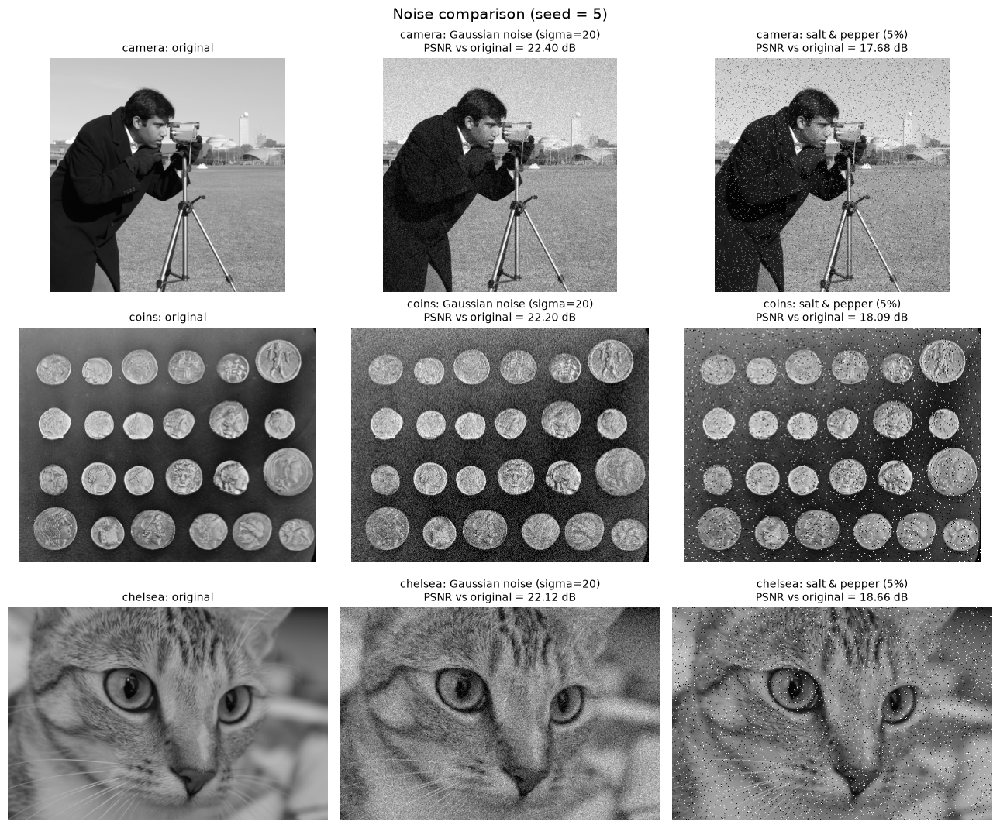

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for r, (name, im) in enumerate(originals.items()):
    panels = [(f"{name}: original", im, ""),
              (f"{name}: Gaussian noise (sigma=20)", noisy[name]["gaussian"], f"\nPSNR vs original = {psnr(im, noisy[name]['gaussian']):.2f} dB"),
              (f"{name}: salt & pepper (5%)", noisy[name]["salt&pepper"], f"\nPSNR vs original = {psnr(im, noisy[name]['salt&pepper']):.2f} dB")]
    for c, (title, img, extra) in enumerate(panels):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title + extra, fontsize=10)
        axes[r, c].axis("off")
fig.suptitle("Noise comparison (seed = 5)", fontsize=14)
plt.tight_layout()
plt.show()

### 7.2 Filter-comparison grids: mean / Gaussian / median on every noisy image
One grid for each kernel size (3×3 is the main one; 5×5 and 7×7 are the repeats). Column 1 is the noisy input. Each panel title gives its PSNR against the **clean original** (R6).

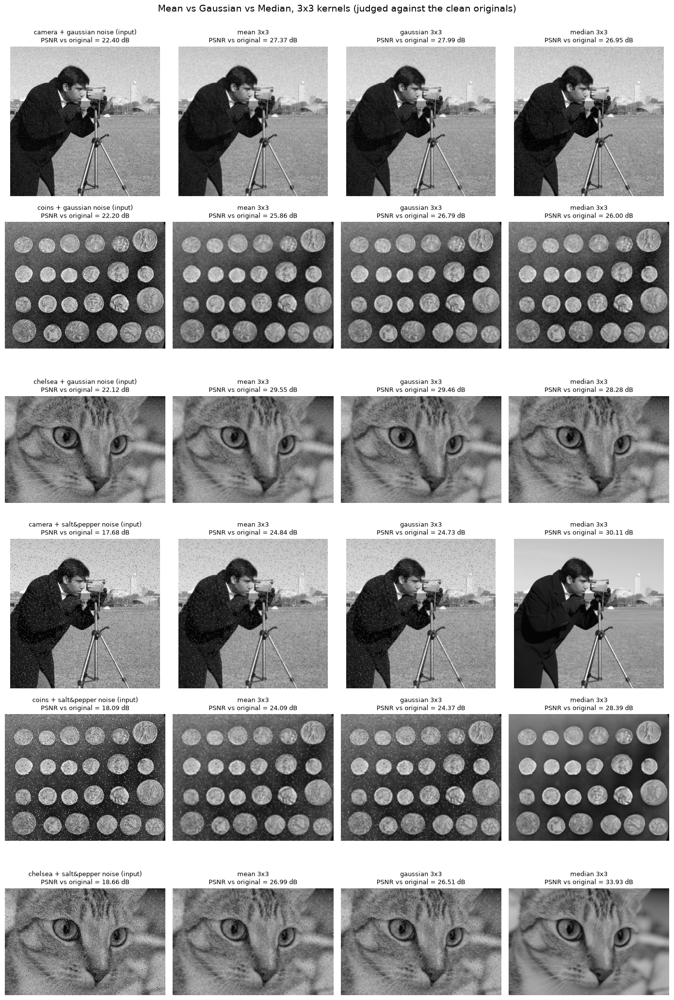

In [16]:
def show_filter_grid(size):
    fig, axes = plt.subplots(6, 4, figsize=(14, 21))
    row = 0
    for nz in ("gaussian", "salt&pepper"):
        for name, im in originals.items():
            panels = [(f"{name} + {nz} noise (input)", noisy[name][nz])]
            panels += [(f"{fname} {size}x{size}", results[(name, nz, fname, size)]) for fname in filters]
            for c, (title, img) in enumerate(panels):
                axes[row, c].imshow(img, cmap="gray", vmin=0, vmax=255)
                axes[row, c].set_title(f"{title}\nPSNR vs original = {psnr(im, img):.2f} dB", fontsize=9)
                axes[row, c].axis("off")
            row += 1
    fig.suptitle(f"Mean vs Gaussian vs Median, {size}x{size} kernels (judged against the clean originals)", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()

show_filter_grid(3)

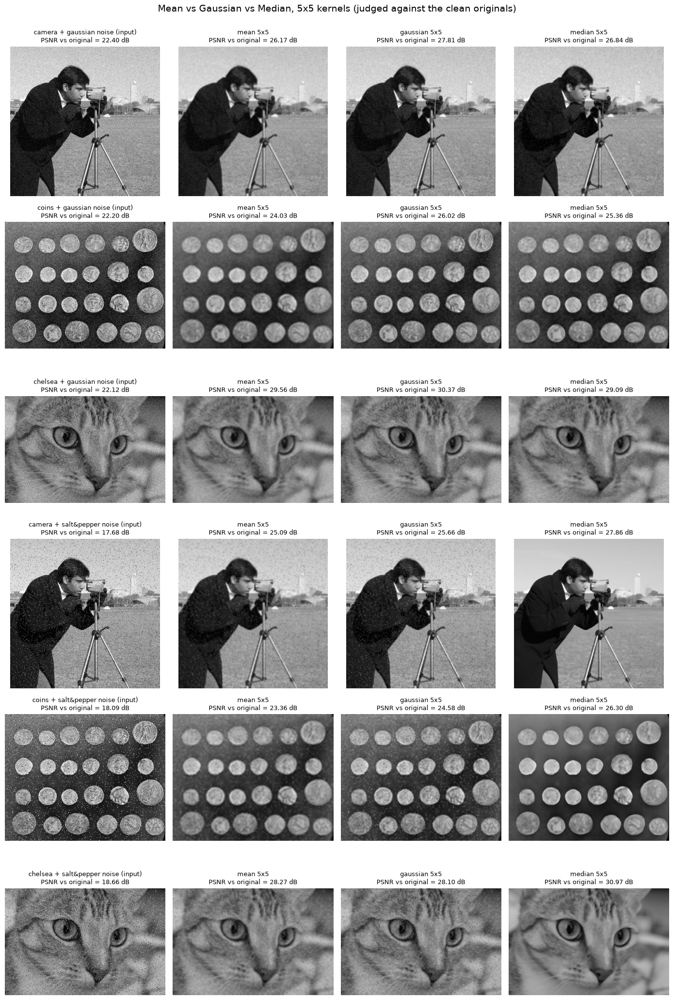

In [17]:
show_filter_grid(5)

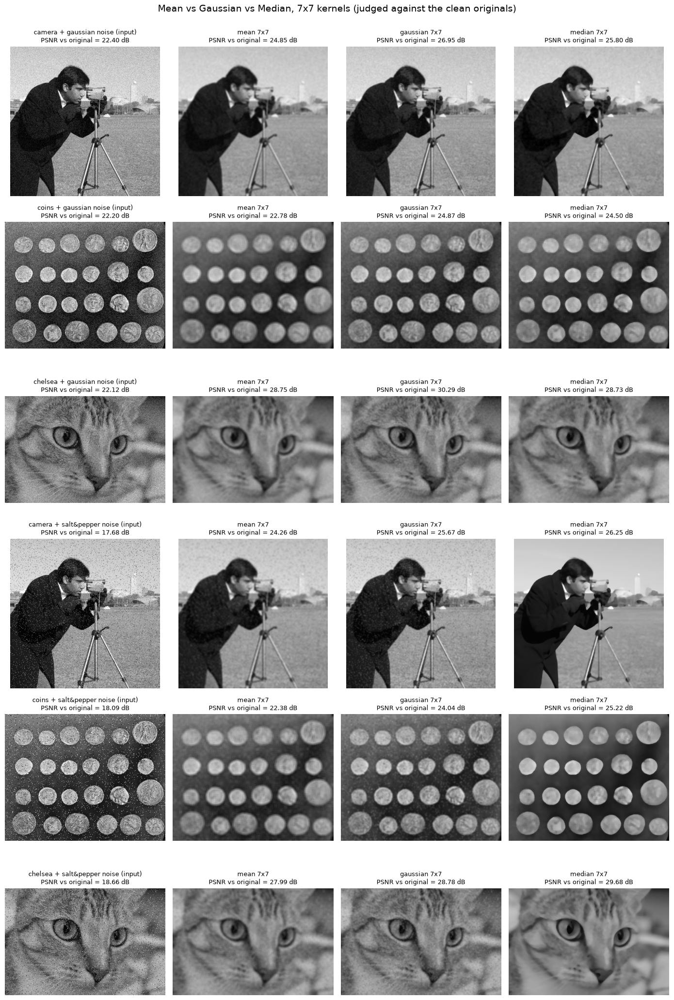

In [18]:
show_filter_grid(7)

### 7.3 Kernel-size grid on the noisiest image (filter × kernel size)
The noisiest image is the one with the lowest PSNR against its clean original (found in section 3).

Noisiest image: camera with salt&pepper noise (PSNR of the noisy input = 17.68 dB)


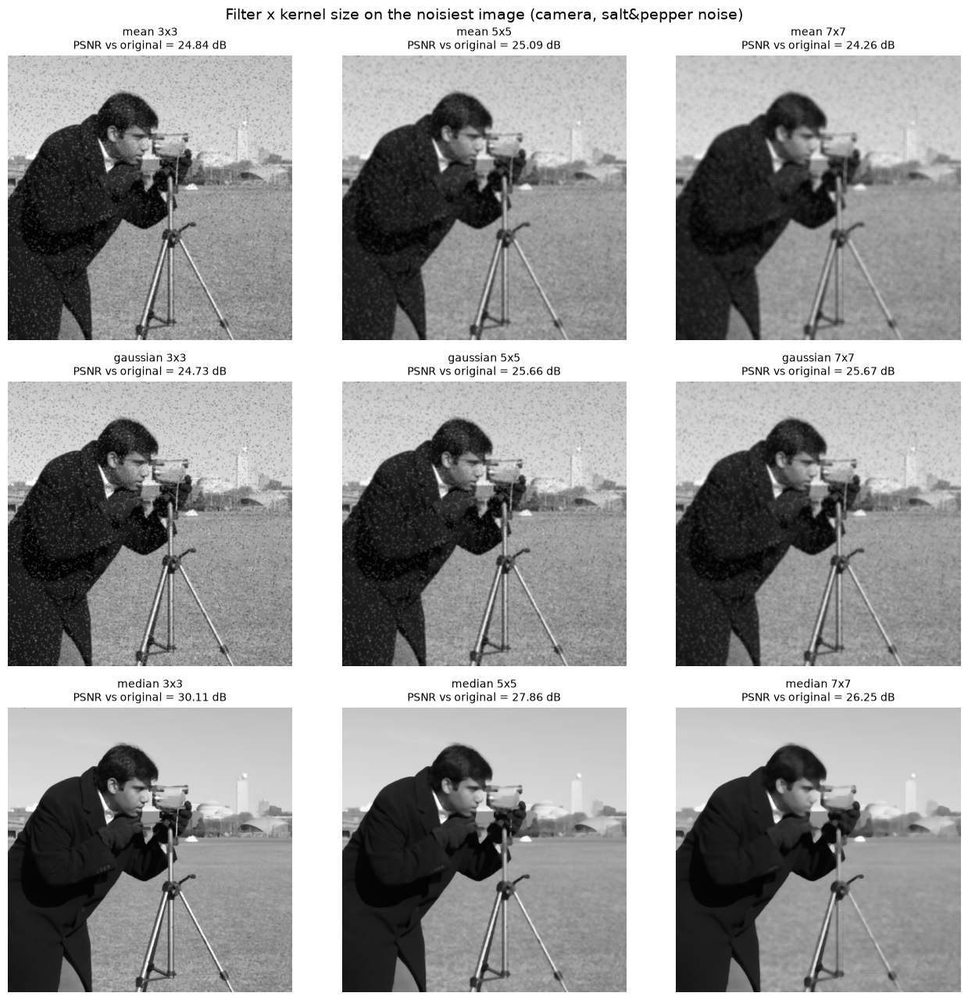

In [19]:
n_name, n_noise = noisiest
im = originals[n_name]
print(f"Noisiest image: {n_name} with {n_noise} noise (PSNR of the noisy input = {psnr(im, noisy[n_name][n_noise]):.2f} dB)")

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for r, fname in enumerate(filters):
    for c, s in enumerate(VALID_SIZES):
        out = results[(n_name, n_noise, fname, s)]
        axes[r, c].imshow(out, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{fname} {s}x{s}\nPSNR vs original = {psnr(im, out):.2f} dB", fontsize=10)
        axes[r, c].axis("off")
fig.suptitle(f"Filter x kernel size on the noisiest image ({n_name}, {n_noise} noise)", fontsize=14)
plt.tight_layout()
plt.show()

### 7.4 Close-ups and region measurements that the observations refer to
**(a) A sharp edge in *coins*:** pixel row 128, where the dark background (grey level about 30) jumps to a bright coin rim (about 200) at x = 317. Mean 5×5 and Gaussian 5×5 are applied to the *clean* image, so the only thing being measured is how each kernel blurs the edge. The 10 %→90 % rise distance says how many pixels the jump has been smeared over (1 px = still a razor-sharp edge).

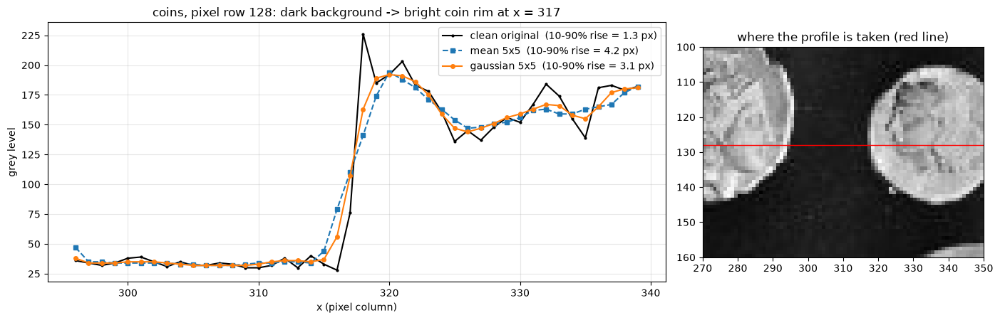

clean original  10-90% rise width = 1.26 px
mean 5x5        10-90% rise width = 4.22 px
gaussian 5x5    10-90% rise width = 3.06 px


In [20]:
ROW, X0, X1, XE = 128, 296, 340, 317          # row, plot window, and the x position of the step
xs = np.arange(X0, X1)
prof = {"clean original": coins[ROW, X0:X1].astype(np.float64),
        "mean 5x5":       mean_filter(coins, 5)[ROW, X0:X1].astype(np.float64),
        "gaussian 5x5":   gaussian_filter(coins, 5)[ROW, X0:X1].astype(np.float64)}

lo = coins[ROW, XE - 12:XE - 4].mean()        # dark side level
hi = coins[ROW, XE + 1:XE + 6].mean()         # bright side level

def first_cross(p, level):
    i = np.argmax(p >= level)                  # first pixel at/above the level
    return xs[i - 1] + (level - p[i - 1]) / (p[i] - p[i - 1])   # linear interpolation

def rise_width(p):
    return first_cross(p, lo + 0.9 * (hi - lo)) - first_cross(p, lo + 0.1 * (hi - lo))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
for (label, p), style in zip(prof.items(), ["k.-", "s--", "o-"]):
    ax[0].plot(xs, p, style, label=f"{label}  (10-90% rise = {rise_width(p):.1f} px)", markersize=4)
ax[0].set_title(f"coins, pixel row {ROW}: dark background -> bright coin rim at x = {XE}")
ax[0].set_xlabel("x (pixel column)"); ax[0].set_ylabel("grey level"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].imshow(coins[100:160, 270:350], cmap="gray", extent=(270, 350, 160, 100))
ax[1].axhline(ROW, color="red", lw=1); ax[1].set_title("where the profile is taken (red line)")
plt.tight_layout()
plt.show()

for label, p in prof.items():
    print(f"{label:15s} 10-90% rise width = {rise_width(p):.2f} px")

**(b) Fine detail in *camera*:** a zoomed region (rows 110–270, columns 230–390) holding the camera body, the thin hanging cord, the tripod-head handle and the distant buildings. Top row: clean original and the three 3×3 filters. Bottom row: the Gaussian-noise input and the three 7×7 filters.

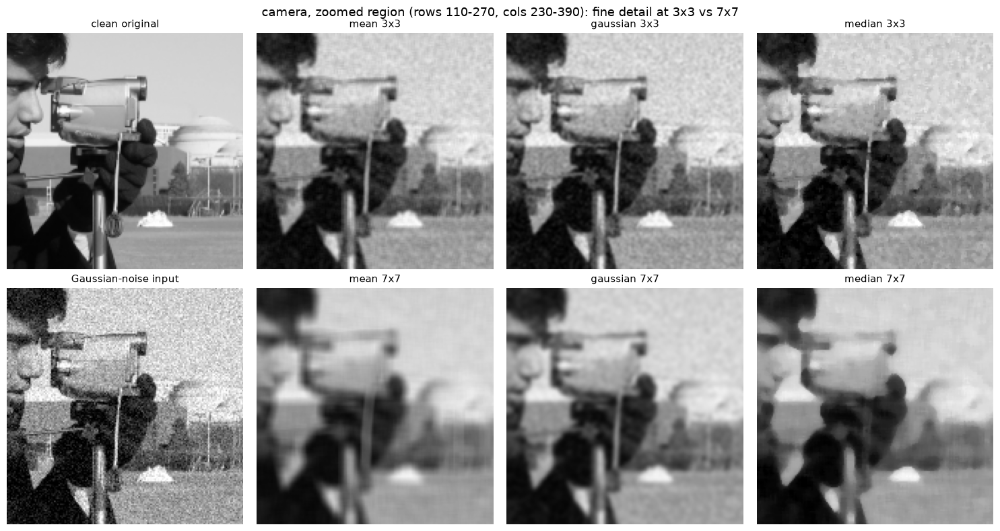

In [21]:
R0, R1, C0, C1 = 110, 270, 230, 390
g_in = noisy["camera"]["gaussian"]
panels = [[("clean original", camera),
           ("mean 3x3",     results[("camera", "gaussian", "mean", 3)]),
           ("gaussian 3x3", results[("camera", "gaussian", "gaussian", 3)]),
           ("median 3x3",   results[("camera", "gaussian", "median", 3)])],
          [("Gaussian-noise input", g_in),
           ("mean 7x7",     results[("camera", "gaussian", "mean", 7)]),
           ("gaussian 7x7", results[("camera", "gaussian", "gaussian", 7)]),
           ("median 7x7",   results[("camera", "gaussian", "median", 7)])]]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for r in range(2):
    for c in range(4):
        title, img = panels[r][c]
        axes[r, c].imshow(img[R0:R1, C0:C1], cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title, fontsize=11); axes[r, c].axis("off")
fig.suptitle("camera, zoomed region (rows 110-270, cols 230-390): fine detail at 3x3 vs 7x7", fontsize=13)
plt.tight_layout(h_pad=2.5)
plt.show()

**(c) Numbers for specific regions** (all compared with the clean original, R6):
* A **flat sky patch** of *camera* (rows 5–54, columns 20–219, 10 000 pixels). It is nearly flat in the clean image (standard deviation about 3 grey levels), so anything that differs from the clean values is leftover noise.
* How much **edge strength** (mean Sobel gradient) each smoothing filter keeps over the whole clean *coins* image, and inside the zoomed *camera* region.

In [22]:
sky = (slice(5, 55), slice(20, 220))
clean_sky = camera[sky].astype(np.float64)
print(f"clean sky patch: mean = {clean_sky.mean():.1f}, std = {clean_sky.std():.2f}\n")

def rms_err(a):
    return np.sqrt(np.mean((a.astype(np.float64) - clean_sky) ** 2))

print("Sky patch of camera, 3x3 filters")
print(f"{'':12s}{'Gaussian noise':>16s}{'salt & pepper':>16s}{'S&P pixels still':>20s}")
print(f"{'':12s}{'RMS error':>16s}{'RMS error':>16s}{'off by > 40 levels':>20s}")
rows = [("noisy input", noisy["camera"]["gaussian"][sky], noisy["camera"]["salt&pepper"][sky])]
for fname in filters:
    rows.append((fname + " 3x3", results[("camera", "gaussian", fname, 3)][sky],
                                 results[("camera", "salt&pepper", fname, 3)][sky]))
for label, gpatch, spatch in rows:
    bad = int((np.abs(spatch.astype(np.float64) - clean_sky) > 40).sum())
    print(f"{label:12s}{rms_err(gpatch):>16.2f}{rms_err(spatch):>16.2f}{bad:>20d}")

def mean_grad(img):
    gx = cv2.Sobel(img.astype(np.float64), cv2.CV_64F, 1, 0)
    gy = cv2.Sobel(img.astype(np.float64), cv2.CV_64F, 0, 1)
    return np.hypot(gx, gy).mean()

print("\nEdge strength kept (mean Sobel gradient, filters applied to the CLEAN image)")
print(f"{'region':22s}{'original':>10s}{'mean':>16s}{'gaussian':>16s}")
for label, im_, sl in [("coins (whole image)", coins, (slice(None), slice(None))),
                       ("camera zoom region", camera, (slice(R0, R1), slice(C0, C1)))]:
    base = mean_grad(im_[sl])
    for s in VALID_SIZES:
        m = mean_grad(mean_filter(im_, s)[sl]); g = gaussian_filter(im_, s)
        g = mean_grad(g[sl])
        print(f"{label:22s}{base:>10.1f}" if s == 3 else f"{'':22s}{'':>10s}", end="")
        print(f"   {s}x{s}: mean {m:5.1f} ({100*m/base:3.0f}%)   gaussian {g:5.1f} ({100*g/base:3.0f}%)")

clean sky patch: mean = 201.4, std = 3.41

Sky patch of camera, 3x3 filters
              Gaussian noise   salt & pepper    S&P pixels still
                   RMS error       RMS error  off by > 40 levels
noisy input            19.96           32.73                 508
mean 3x3                6.46           11.34                 160
gaussian 3x3            7.28           12.63                 283
median 3x3              8.09            0.56                   0

Edge strength kept (mean Sobel gradient, filters applied to the CLEAN image)
region                  original            mean        gaussian
coins (whole image)         70.8   3x3: mean  49.6 ( 70%)   gaussian  53.0 ( 75%)
                                   5x5: mean  39.3 ( 56%)   gaussian  45.9 ( 65%)
                                   7x7: mean  34.1 ( 48%)   gaussian  39.7 ( 56%)
camera zoom region          80.8   3x3: mean  63.6 ( 79%)   gaussian  66.8 ( 83%)
                                   5x5: mean  51.3 ( 63%)   gau

## 8. Observations
All judgements use the **clean originals** as the reference (R6). Each PSNR quoted is a "filtered vs clean original" value from the table in section 5 or from the panel titles of the grids. Higher PSNR means closer to the clean picture. The wording is plain on purpose, and every answer points to a place in my own figures.

**Q1. Which filter looks best on Gaussian noise, and which looks worst?**
* **Best: the Gaussian filter (3×3).** It has the highest average PSNR, **28.08 dB** (the noisy input was 22.24 dB), against 27.59 dB for the mean and 27.08 dB for the median. In the 3×3 grid, *camera* + Gaussian noise (row 1), the grain is gone from the coat but the tripod legs and the camera outline are still crisp.
* **Worst: the median filter (3×3).** In the *coins* + Gaussian row of the grid it scores 26.00 dB against 26.79 dB for the Gaussian filter. In the zoomed camera crop (section 7.4b, top row) the sky above the buildings still looks mottled after the 3×3 median. In the flat sky patch it leaves an RMS error of 8.09, against 6.46 for the mean and 7.28 for the Gaussian.
* **Why:** Gaussian noise nudges *every* pixel a little. There are no extreme outliers for the median to throw away, so it just picks one noisy value. Averaging cancels the up-and-down errors instead.
* **Honest note:** the gap is small (about 1 dB). The mean filter is even slightly ahead on *chelsea* at 3×3 (29.55 vs 29.46 dB), and it is the best of the three inside the flat sky patch. The Gaussian filter wins overall because it blurs the edges less (see Q3).

**Q2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**
* **Best: the median filter (3×3).** Average **30.81 dB**, against about 25.3 dB (mean) and 25.2 dB (Gaussian). In the grid, the *camera* + salt-and-pepper row, the median result has clean sky and grass with no dots at all. In the flat sky patch the median leaves **0** pixels that are still wrong by more than 40 grey levels (RMS error 0.56), while the mean leaves 160 (RMS 11.34) and the Gaussian leaves 283 (RMS 12.63).
* **Why the mean and Gaussian fail:** a white (255) or black (0) dot is a huge number, and averaging *includes* it. The dot is not removed, only smeared into a grey smudge over its 3×3 neighbourhood. This is visible as grey speckles on the grass and coat in the mean and Gaussian columns of the *camera* row. Dry-run Exercise 1 shows the same thing: one 255 spike in a flat area of 40 gives 64 with the mean and 94 with the Gaussian.
* The Gaussian filter is the *worst* here (283 bad pixels vs 160 for the mean) because it gives the centre pixel the biggest weight (4/16). If the centre is the noisy pixel, the spike is counted even more strongly.
* **Why the median works:** sorted neighbours put a 0 or a 255 at the very end of the list, never in the middle. The middle value is a normal pixel, as long as less than half the window is corrupted. At 5 % noise that is almost always true.

**Q3. How do the mean and Gaussian filters compare on a sharp edge?**
* In section 7.4a (*coins*, pixel row 128, dark background jumping to a bright coin rim at x = 317), the clean edge rises from 10 % to 90 % in about **1.3 px**. After a 5×5 **mean** the same jump is smeared over **4.2 px**, and after a 5×5 **Gaussian** over **3.1 px**. In the plot, the blue mean curve leaves the dark level earlier and climbs more slowly, while the orange Gaussian curve stays flat longer and then rises more steeply.
* Over the whole *coins* image, the 5×5 Gaussian keeps **65 %** of the original edge strength, but the 5×5 mean keeps only **56 %** (at 3×3: 75 % vs 70 %).
* **Why:** the mean gives a faraway pixel on the other side of the edge the same vote as the pixel next to it. The Gaussian gives the near pixels more weight, so the edge is spread less. That is also why the Gaussian filter has the higher PSNR on most of the Gaussian-noise images.

**Q4. What happens to fine detail at 7×7?**
* Look at the zoomed *camera* region (section 7.4b). In the clean original, the thin hanging cord under the camera and the horizontal tripod-head handle are clearly visible. They are still faintly there at 3×3, but at **7×7 they are gone in all three filters**, and the distant domed building turns into a soft blob.
* Edge strength in that region drops from 79 % (mean) and 83 % (Gaussian) at 3×3 to **53 %** and **65 %** at 7×7.
* The median at 7×7 keeps the large outlines (the camera body and glove) but rounds off and merges small shapes. In the kernel-size grid (section 7.3), the tripod legs in the *median* row get thinner and the background buildings smear as the kernel grows.
* The numbers say the same: on the noisiest image (*camera*, salt-and-pepper) the median falls from 30.11 dB (3×3) to 27.86 dB (5×5) to 26.25 dB (7×7). A larger kernel removes more noise but destroys more real detail, so a bigger kernel is not always better.

**Q5. Why must the kernel size be odd?**
* An odd size (3, 5, 7) has one **centre pixel** with the same number of neighbours on every side. The output pixel is written exactly at that centre. This is the situation in Exercise 1 (the 255 spike sits in the middle of the 3×3 window) and Exercise 2 (pixel (0, 0) is the middle of its padded window).
* A 4×4 window has no centre pixel. The result would belong *between* pixels, so the whole image would shift by half a pixel, and the padding would be lopsided.
* OpenCV refuses it too: in section 4, `cv2.medianBlur(coins, 4)` stopped with an assertion error that says `ksize % 2 == 1`.

## 9. Viva preparation
I prepared brief answers to all six questions, so that I am ready for whichever two are asked.

1. **What is a kernel?** A small grid of numbers (for example 3×3) that slides over the image. For each pixel, the pixels under the grid are multiplied by the matching weights and added up. The weights decide what the filter does: equal weights blur, a bell-shaped grid blurs gently, other patterns find edges.

2. **Apply a 3×3 mean kernel to a window given on the spot.** Add the nine numbers and divide by 9. For the spike window of Exercise 1: (8 × 40 + 255) / 9 = 575 / 9 = 63.9, so **64**. For the corner window of Exercise 2: 330 / 9 = 36.7, so **37**.

3. **Why does the median remove a 255 spike but the mean does not?** The mean adds the spike into the total, so it pulls the answer up (40 becomes 64 in Exercise 1). The median sorts the nine values first. The spike lands at the very end of the list, and the middle (5th) value is still 40.

4. **Why do the Gaussian weights sum to 16, and why divide by it?** The 1-D row is 1-2-1, which adds up to 4. The 3×3 kernel is that row times its transpose, and (1 + 2 + 1)² = 16. Dividing by 16 makes the weights sum to 1 (R3), so a flat area keeps its brightness (a flat 40 stays 16 × 40 / 16 = 40). Without the division the image would come out 16 times too bright and clip to 255.

5. **Why do we pad the border before filtering?** A border pixel has no neighbours on one side, so the window would hang off the image. Without padding we would either lose the border pixels (the output would shrink, breaking R1) or have missing values. Reflect padding mirrors the nearest pixels outward so every pixel gets a full window. In Exercise 2 this supplied the 50, 40, 50 and 20 values around pixel (0, 0).

6. **Which filter for salt-and-pepper noise, and why?** The **median**. The black and white dots are extreme values that end up at the ends of the sorted list, so the median ignores them. In my results it reached 30.81 dB on average, against about 25 dB for the mean and Gaussian filters.

## 10. Final integrity check

In [23]:
for k, v in originals.items():
    assert fingerprint(v) == orig_hash[k] and not v.flags.writeable
print("PASS: the three original images are unchanged and still read-only.")

PASS: the three original images are unchanged and still read-only.
